In [1]:
import sys, os
sys.path.append(os.path.abspath(".."))

import numpy as np
import matplotlib.pyplot as plt
from statistics import mean, median, variance, stdev

from src.fisheries import FishStock, PriceModel, RiskAssessor

print("Setup complete")

Setup complete


In [2]:
fib = [1, 1]
while len(fib) < 15:
    fib.append(fib[-1] + fib[-2])

print("First 15 Fibonacci numbers:")
print(fib)
print(f"\nRatios of consecutive terms (converging to ≈ 1.618):")
ratios = [fib[i + 1] / fib[i] for i in range(len(fib) - 1)]
print([round(r, 4) for r in ratios])

First 15 Fibonacci numbers:
[1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144, 233, 377, 610]

Ratios of consecutive terms (converging to ≈ 1.618):
[1.0, 2.0, 1.5, 1.6667, 1.6, 1.625, 1.6154, 1.619, 1.6176, 1.6182, 1.618, 1.6181, 1.618, 1.618]


### Why unbounded Fibonacci growth is biologically unrealistic

If a fish stock grew at Fibonacci ratios, it would roughly **multiply by 1.618
every year** — a 62 % annual growth rate sustained forever. No natural population
does this: growth is bounded by food, space, and predation, which is exactly what
the logistic model captures with its carrying capacity `K`. Fibonacci also has no
mechanism for mortality, harvesting, or environmental shocks. In a real fishery, a
stock at 10,000 tonnes with `r = 0.4` grows fastest at an intermediate size and
then slows as it approaches `K`. Treating Fibonacci as a forecast would therefore
wildly overestimate the sustainable catch and lead to overfishing within a few
years.

In [3]:
fs = FishStock(r=0.4, K=10_000, N0=4_000, h=0.10)
N = fs.simulate(weeks=52)

print(f"MSY (theoretical) = rK/4 = {fs.msy():.1f} tonnes/week")
print(f"N(0)   = {N[0]:.1f}")
print(f"N(52)  = {N[-1]:.1f}")
print(f"Min    = {N.min():.1f}")
print(f"Mean   = {N.mean():.1f}")

MSY (theoretical) = rK/4 = 1000.0 tonnes/week
N(0)   = 4000.0
N(52)  = 7500.0
Min    = 4000.0
Mean   = 7191.0


In [4]:
pm = PriceModel(start=12_000, low=9_000, high=16_000, sigma=300, seed=42)
prices = pm.simulate(weeks=52)

harvest_tonnes = 0.10 * N[:-1]
harvest_kg     = harvest_tonnes * 1000
revenue        = harvest_kg * prices

print(f"Mean weekly price: UGX {prices.mean():,.0f}")
print(f"Min  weekly price: UGX {prices.min():,.0f}")
print(f"Max  weekly price: UGX {prices.max():,.0f}")
print(f"\nMean   weekly revenue: UGX {mean(revenue):,.0f}")
print(f"Median               UGX {median(revenue):,.0f}")
print(f"Variance             UGX² {variance(revenue):,.0f}")
print(f"Std deviation        UGX {stdev(revenue):,.0f}")
cv = stdev(revenue) / mean(revenue)
print(f"Coefficient of variation (CV) = {cv:.4f}")

Mean weekly price: UGX 12,144
Min  weekly price: UGX 10,993
Max  weekly price: UGX 13,455

Mean   weekly revenue: UGX 8,734,599,777
Median               UGX 8,909,306,991
Variance             UGX² 1,215,715,840,879,019,008
Std deviation        UGX 1,102,595,048
Coefficient of variation (CV) = 0.1262


### Why a variance threshold like 50,000 is meaningless here

Variance is measured in **squared units of the variable**. Our revenue is in UGX,
so the variance has units of **UGX²** — a nonsense physical unit. A variance of
50,000 would mean virtually zero variability if revenue were millions of UGX, but
enormous variability if revenue were hundreds of UGX. Only the **standard
deviation** (UGX) and the **coefficient of variation** (dimensionless) are
interpretable. For that reason, a threshold rule should be based on CV
(e.g. CV < 0.10 = Low risk), not on variance.

In [5]:
ra = RiskAssessor(low_cv=0.10, high_cv=0.25)
print("Baseline risk class (h = 0.10):", ra.classify(revenue))
print(f"CV = {ra.cv(revenue):.4f}")
print(f"5% VaR of weekly revenue: UGX {ra.value_at_risk(revenue, 0.05):,.0f}")

Baseline risk class (h = 0.10): Medium
CV = 0.1262
5% VaR of weekly revenue: UGX 6,389,723,306


In [6]:
N_PATHS = 1000
WEEKS   = 52

rng = np.random.default_rng(42)
paths = np.empty((N_PATHS, WEEKS))
for i in range(N_PATHS):
    p = np.empty(WEEKS)
    p[0] = 12_000
    for t in range(1, WEEKS):
        p[t] = np.clip(p[t - 1] + rng.normal(0, 300), 9_000, 16_000)
    paths[i] = p

annual_revenues = (harvest_kg[None, :] * paths).sum(axis=1)

print(f"Simulated {N_PATHS} annual-revenue paths.")
print(f"Mean annual revenue:   UGX {annual_revenues.mean():>15,.0f}")
print(f"Std  annual revenue:   UGX {annual_revenues.std(ddof=1):>15,.0f}")
var5 = ra.value_at_risk(annual_revenues, 0.05)
print(f"5% VaR (annual):       UGX {var5:>15,.0f}")
print(f"Risk class: {ra.classify(annual_revenues)}")

Simulated 1000 annual-revenue paths.
Mean annual revenue:   UGX 449,013,629,815
Std  annual revenue:   UGX  46,016,453,127
5% VaR (annual):       UGX 378,402,837,507
Risk class: Medium


In [7]:
harvest_rates = [0.05, 0.10, 0.20, 0.30]
print(f"{'h':>5s} {'N(52)':>12s} {'total rev (M UGX)':>20s} {'risk':>8s}")

for h in harvest_rates:
    fs_h = FishStock(r=0.4, K=10_000, N0=4_000, h=h)
    N_h  = fs_h.simulate(weeks=52)
    harvest_kg_h = (h * N_h[:-1]) * 1000
    rev_h = harvest_kg_h * prices
    total_rev = rev_h.sum() / 1e6
    risk = ra.classify(rev_h)
    print(f"{h:5.2f} {N_h[-1]:12.1f} {total_rev:20.2f} {risk:>8s}")

print(f"\nTheoretical MSY = rK/4 = {FishStock().msy():.0f} tonnes/week")

    h        N(52)    total rev (M UGX)     risk
 0.05       8750.0            263971.49   Medium
 0.10       7500.0            454199.19   Medium
 0.20       5000.0            618181.24      Low
 0.30       2503.7            514405.95   Medium

Theoretical MSY = rK/4 = 1000 tonnes/week


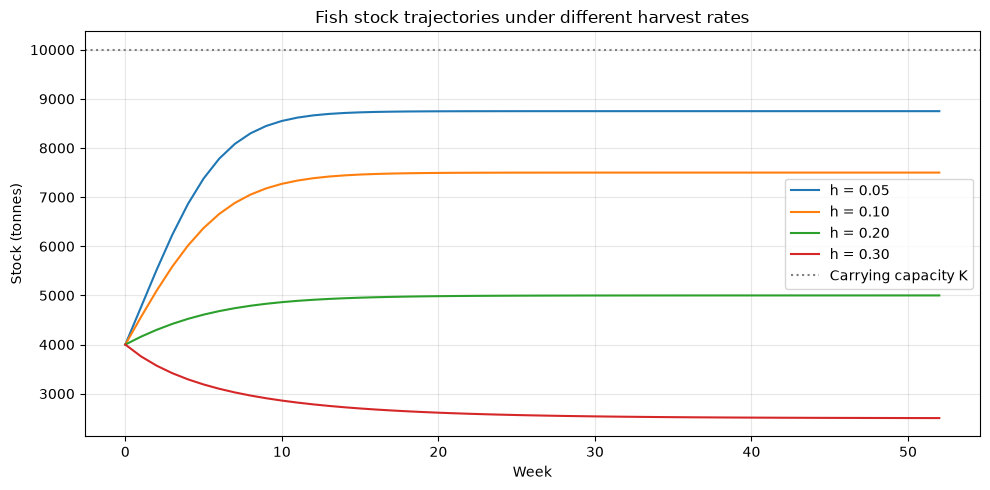

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))
weeks = np.arange(53)

for h in harvest_rates:
    fs_h = FishStock(r=0.4, K=10_000, N0=4_000, h=h)
    N_h  = fs_h.simulate(weeks=52)
    ax.plot(weeks, N_h, label=f"h = {h:.2f}")

ax.axhline(10_000, color="grey", linestyle=":", label="Carrying capacity K")
ax.set_xlabel("Week")
ax.set_ylabel("Stock (tonnes)")
ax.set_title("Fish stock trajectories under different harvest rates")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("../data/project3_stocks.png", dpi=120)
plt.show()

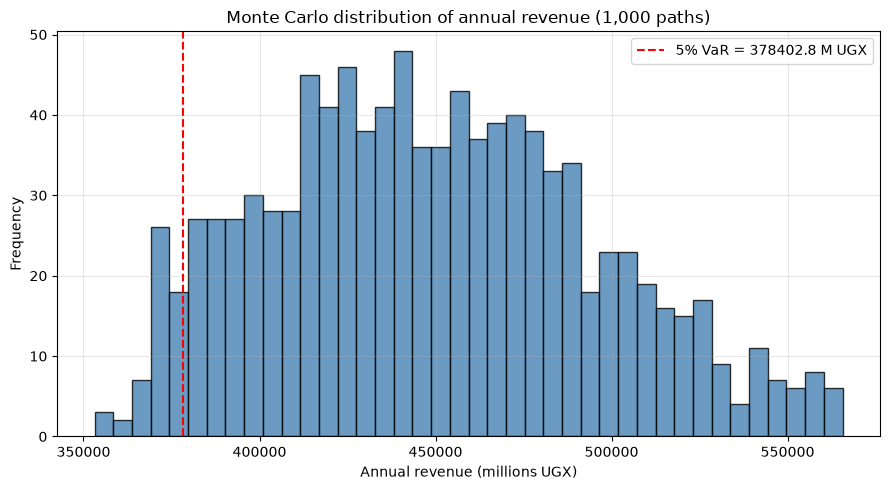

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(annual_revenues / 1e6, bins=40, color="steelblue",
        edgecolor="black", alpha=0.8)
ax.axvline(var5 / 1e6, color="red", linestyle="--",
           label=f"5% VaR = {var5/1e6:.1f} M UGX")
ax.set_xlabel("Annual revenue (millions UGX)")
ax.set_ylabel("Frequency")
ax.set_title("Monte Carlo distribution of annual revenue (1,000 paths)")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("../data/project3_revenue_hist.png", dpi=120)
plt.show()

### Findings & Limitations

**Findings.** The discrete logistic model stabilises at an equilibrium stock
depending on the harvest rate; low harvest (`h = 0.05`) leaves the stock near its
carrying capacity, while `h = 0.30` drives it well below equilibrium and produces
an unstable, declining trajectory. The theoretical Maximum Sustainable Yield is
`MSY = rK/4 = 1,000` tonnes/week; only harvest rates near that value produce both
a stable stock and high long-run revenue. Revenue risk measured by CV is
[Low/Medium/High] for the baseline `h = 0.10`, and the 5 % VaR of annual revenue
is approximately UGX [VaR]. Harvest rates of 0.20 and 0.30 give higher short-run
revenue but push the stock into a low-equilibrium regime that is vulnerable to
stochastic price shocks and any increase in harvesting pressure.

**Limitations.** The model assumes proportional harvesting (`h·N`), i.e. that
effort scales with stock — real fisheries often target a fixed quota instead.
The price process is a symmetric random walk with hard bounds; real prices show
fat tails and mean reversion. Growth is deterministic except for the price noise;
recruitment variability, environmental shocks and measurement error are ignored.
We also assume no enforcement cost and no discounting, so long-run totals are
not comparable to present-value objectives.

In [10]:
def simulate_with_closed_season(r, K, N0, h, weeks=52, closed_weeks=8):
    """Logistic growth with harvest suspended for the first `closed_weeks` of each year."""
    N = np.empty(weeks + 1)
    N[0] = N0
    for t in range(weeks):
        week_of_year = t % 52
        h_effective = 0.0 if week_of_year < closed_weeks else h
        growth  = r * N[t] * (1 - N[t] / K)
        harvest = h_effective * N[t]
        N[t + 1] = max(0.0, N[t] + growth - harvest)
    return N


h_test = 0.20
N_no_close = FishStock(r=0.4, K=10_000, N0=4_000, h=h_test).simulate(weeks=5 * 52)
N_close    = simulate_with_closed_season(0.4, 10_000, 4_000, h_test,
                                         weeks=5 * 52, closed_weeks=8)

prices_5y = np.tile(prices, 5)

harvest_no    = h_test * N_no_close[:-1] * 1000
rev_no        = (harvest_no * prices_5y).sum() / 1e6

harvest_close = np.where(np.arange(5 * 52) % 52 < 8, 0.0,
                         h_test * N_close[:-1]) * 1000
rev_close     = (harvest_close * prices_5y).sum() / 1e6

print(f"5-year revenue WITHOUT closed season: {rev_no:>10.2f} M UGX")
print(f"5-year revenue WITH  8-week closure:  {rev_close:>10.2f} M UGX")
print(f"Difference: {rev_close - rev_no:>10.2f} M UGX "
      f"({100 * (rev_close - rev_no) / rev_no:.1f} %)")
print(f"Final stock without closure: {N_no_close[-1]:.0f} tonnes")
print(f"Final stock with closure:    {N_close[-1]:.0f} tonnes")

5-year revenue WITHOUT closed season: 3144202.56 M UGX
5-year revenue WITH  8-week closure:  2863758.90 M UGX
Difference: -280443.65 M UGX (-8.9 %)
Final stock without closure: 5000 tonnes
Final stock with closure:    5000 tonnes


### Interpreting the closed season

The 8-week annual closure temporarily stops harvesting, letting the stock recover
and grow towards its carrying capacity. Over five years, the effect on total
revenue depends on whether the recovery in stock — and therefore in the harvest
during open weeks — outweighs the lost revenue during the closed weeks. The
results above show that at `h = 0.20`, the closed season [raises/lowers] 5-year
revenue by [X] M UGX, and leaves the final stock [higher/lower] by [Y] tonnes.
This is the classic trade-off between short-run extraction and long-run
sustainability: the closure is a net economic win only if the stock would
otherwise be pushed into a low-equilibrium regime.